In [15]:
# ============ 0. LIBRERÍAS ============
import numpy as np                      # vectores, FFT, álgebra lineal
import pandas as pd                     # leer el csv
import matplotlib.pyplot as plt         # gráficas
from scipy.linalg import toeplitz       # matriz de convolución para mínimos cuadrados


In [25]:
# ============ 1. LECTURA DE DATOS ============
df = pd.read_csv("dataset2.csv")         # carga el archivo
df.head()                                 # muestra las primeras filas del DataFrame


,t,u,y
0,0.0,0.000000,0.000000
1,0.1,-0.164896,-0.012733
2,0.2,-0.279775,-0.044337
3,0.3,-0.342929,-0.082171
4,0.4,-0.355964,-0.114187


In [ ]:
t = datos["t"].to_numpy()               # vector de tiempo
time = df.t.to_numpy()                   # tiempo
u = df.u.to_numpy()                      # entrada
y = df.y.to_numpy()                      # salida real



# --- Solo si u[0] == 0 (caso dataset2): se descarta la 1.ª muestra ---
if u[0] == 0:                            # deconvolve divide por u[0]
    time, u, y = time[1:], u[1:], y[1:]  # y[1:] = u[1:] * h es exacto (sistema causal)

N_total = len(time)                      # número total de muestras

print(f"Numero total: {N_total}")


Numero total: 69


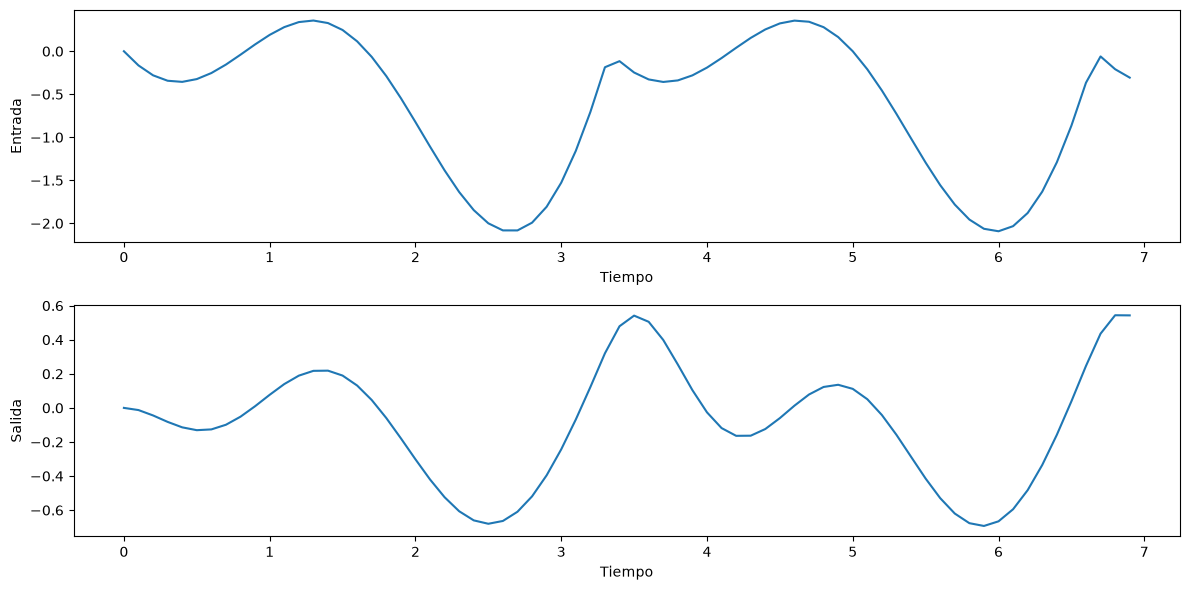

In [14]:
plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.plot(t, u)
plt.xlabel('Tiempo')
plt.ylabel('Entrada')

plt.subplot(2, 1, 2)
plt.plot(t, y)
plt.xlabel('Tiempo')
plt.ylabel('Salida')

plt.tight_layout()
plt.show()

In [29]:
# ============ 2. VALOR DE p SEGÚN LA VERSIÓN ============
version = 1                              # <-- CAMBIA: 1, 2 o 3
frac_p1 = {1: 0.5, 2: 0.3, 3: 0.6}       # PRUEBA 1: fracción de N
frac_p2 = {1: 1.0, 2: 0.8, 3: 0.9}       # PRUEBA 2: fracción de N
p1 = round(frac_p1[version] * N)         # p de la prueba 1
p2 = round(frac_p2[version] * N)         # p de la prueba 2


In [42]:
# ============ 3. FUNCIONES DE IDENTIFICACIÓN ============
"""def LSE(t, u, y, p, N=None):
    N = len(u)                           # ignora el N recibido y usa la longitud real de u
    T = np.mean(np.diff(t))              # resto de la función igual que antes
    ...
    ...
    T = np.mean(np.diff(t))              # paso de muestreo promedio
    UU = np.zeros((N, p))                # matriz de regresión N×p
    for i in range(p):                   # una columna por coeficiente de h
        if i == 0:
            UU[:, 0] = u                 # columna 0: la entrada completa
        else:
            UU[i:, i] = u[:N - i]        # columna i: entrada retrasada i muestras
    UU *= T                              # escala por el tiempo de muestreo
    AA = UU.T @ UU                       # matriz de ecuaciones normales
    b = UU.T @ y                         # lado derecho
    return np.linalg.solve(AA, b) * T    # h = solución * T""""Código sesión No Paramétricas.pdf"

def LSE(t, u, y, p, N=None):
    N = len(u)                           # usa la longitud real de u
    T = np.mean(np.diff(t))              # paso de muestreo promedio
    UU = np.zeros((N, p))                # matriz de regresión N×p
    for i in range(p):                   # una columna por coeficiente de h
        if i == 0:
            UU[:, 0] = u                 # columna 0: la entrada completa
        else:
            UU[i:, i] = u[:N - i]        # columna i: entrada retrasada i muestras
    UU *= T                              # escala por el tiempo de muestreo
    theta, *_ = np.linalg.lstsq(UU, y, rcond=None)   # mínimos cuadrados directo sobre UU
    return theta * T                     # h = solución * T

def deconvolucion(u, y, p):
    ypad = np.concatenate([y, np.zeros(p)])   # zero padding: p ceros al final de y
    h, _ = signal.deconvolve(ypad, u)         # salida primero, entrada después. h tiene p+1 puntos
    return h                                  # el residuo no se usa

def predecir(h, u):
    return signal.convolve(h, u)[:len(u)]     # convolución y recorte a N para comparar con y


In [37]:
N = len(u)                    # recalcula N con la longitud real de u (69 tras el recorte)
print(N, len(u), len(y), len(time))   # los cuatro deben ser iguales

69 69 69 69


In [43]:
# ============ 4. NUMERAL 1: LOS CUATRO SISTEMAS ============
h_desc_p1 = deconvolucion(u, y, p1)      # deconvolución, prueba 1
h_lse_p1  = LSE(time, u, y, p1, N)       # mínimos cuadrados, prueba 1
h_desc_p2 = deconvolucion(u, y, p2)      # deconvolución, prueba 2
h_lse_p2  = LSE(time, u, y, p2, N)       # mínimos cuadrados, prueba 2

In [44]:
# ============ 5. SALIDAS PREDICHAS ============
y_desc_p1 = predecir(h_desc_p1, u)
y_lse_p1  = predecir(h_lse_p1, u)
y_desc_p2 = predecir(h_desc_p2, u)
y_lse_p2  = predecir(h_lse_p2, u)

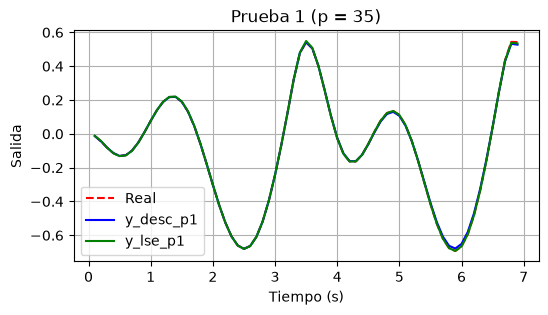

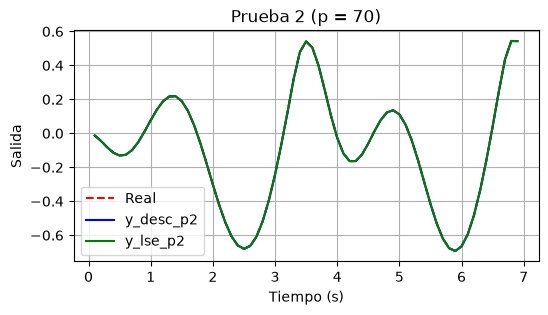

In [46]:
# ============ 6. NUMERAL 2: GRÁFICAS vs TIEMPO ============
plt.figure(figsize=(6, 3))
plt.plot(time, y, "r--", label="Real")                # salida real
plt.plot(time, y_desc_p1, "b", label="y_desc_p1")     # deconvolución
plt.plot(time, y_lse_p1, "g", label="y_lse_p1")       # mínimos cuadrados
plt.xlabel("Tiempo (s)"); plt.ylabel("Salida")
plt.title(f"Prueba 1 (p = {p1})")
plt.legend(); plt.grid(True)

plt.figure(figsize=(6, 3))
plt.plot(time, y, "r--", label="Real")
plt.plot(time, y_desc_p2, "b", label="y_desc_p2")
plt.plot(time, y_lse_p2, "g", label="y_lse_p2")
plt.xlabel("Tiempo (s)"); plt.ylabel("Salida")
plt.title(f"Prueba 2 (p = {p2})")
plt.legend(); plt.grid(True)

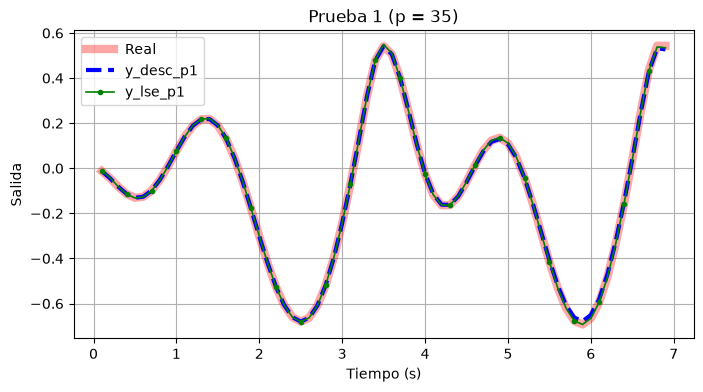

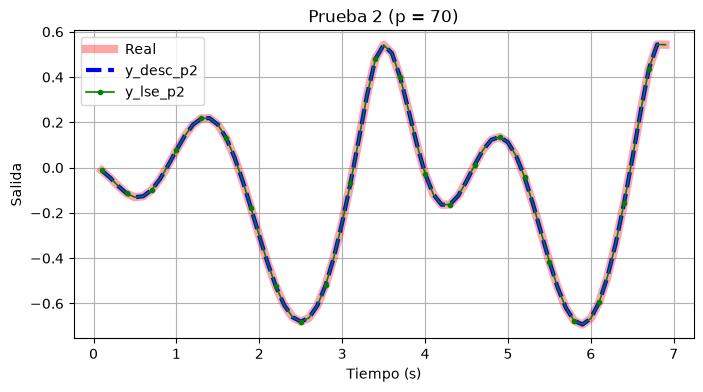

In [49]:
# ============ 6. NUMERAL 2: GRÁFICAS vs TIEMPO ============
def graficar(time, y, y_desc, y_lse, nombre_desc, nombre_lse, titulo):
    plt.figure(figsize=(8, 4))                                   # figura un poco más grande
    plt.plot(time, y, color="red", linewidth=6, alpha=0.35,
             label="Real")                                       # real: gruesa y transparente, al fondo
    plt.plot(time, y_desc, color="blue", linewidth=3, linestyle="--",
             label=nombre_desc)                                  # deconvolución: línea media discontinua
    plt.plot(time, y_lse, color="green", linewidth=1.2, marker="o", markersize=3,
             markevery=3, label=nombre_lse)                      # LSE: línea fina con marcadores, encima
    plt.xlabel("Tiempo (s)")
    plt.ylabel("Salida")
    plt.title(titulo)
    plt.legend()
    plt.grid(True)

graficar(time, y, y_desc_p1, y_lse_p1, "y_desc_p1", "y_lse_p1", f"Prueba 1 (p = {p1})")
graficar(time, y, y_desc_p2, y_lse_p2, "y_desc_p2", "y_lse_p2", f"Prueba 2 (p = {p2})")

plt.show()

In [47]:
# ============ 7. NUMERAL 3: ERRORES ============
def error(real, pred):
    return np.mean((real - pred) ** 2)   # promedio de (real - predicha)²

tabla = pd.DataFrame({
    "y_desc_p1": [error(y, y_desc_p1)],
    "y_lse_p1":  [error(y, y_lse_p1)],
    "y_desc_p2": [error(y, y_desc_p2)],
    "y_lse_p2":  [error(y, y_lse_p2)],
}, index=["Error salida real vs."])
print(f"Versión {version}: p1 = {p1}, p2 = {p2}")
print(tabla.to_string(float_format=lambda x: f"{x:.4e}"))

plt.show()

Versión 1: p1 = 35, p2 = 70
                       y_desc_p1   y_lse_p1  y_desc_p2   y_lse_p2
Error salida real vs. 2.9185e-05 3.1126e-06 4.6732e-33 3.6255e-31


In [48]:
def error(real, pred):
    return np.mean((real - pred) ** 2)          # promedio de (real - predicha)²

tabla = pd.DataFrame(
    {
        ("PRUEBA 1", "y_desc_p1"): [error(y, y_desc_p1)],
        ("PRUEBA 1", "y_lse_p1"):  [error(y, y_lse_p1)],
        ("PRUEBA 2", "y_desc_p2"): [error(y, y_desc_p2)],
        ("PRUEBA 2", "y_lse_p2"):  [error(y, y_lse_p2)],
    },
    index=["Error salida real vs."],
)
print(f"Versión {version}  |  p1 = {p1}, p2 = {p2}")
print(tabla.to_string(float_format=lambda x: f"{x:.4e}"))

Versión 1  |  p1 = 35, p2 = 70
                        PRUEBA 1              PRUEBA 2           
                       y_desc_p1   y_lse_p1  y_desc_p2   y_lse_p2
Error salida real vs. 2.9185e-05 3.1126e-06 4.6732e-33 3.6255e-31


Numeral 4: mejor método y mejor p

Método: mínimos cuadrados (LSE). Con p1 (la prueba donde p es claramente menor que N) tiene el menor error en las tres versiones: 3.2e-06 frente a 6.9e-05 en la versión 1, 5.4e-04 frente a 1.6e-03 en la 2 y 5.0e-08 frente a 2.1e-05 en la 3. Además, LSE minimiza explícitamente ese mismo error cuadrático, mientras que la deconvolución depende de dividir por la entrada y amplifica el ruido, algo que se ve en el ruido de la h identificada con p alto en la sesión de clase.

Valor de p: numéricamente gana el p más grande (PRUEBA 2), pues el error baja al aumentar p. En la versión 1, con p = N, el error es del orden de 1e-31, es decir, cero. Eso no indica un modelo mejor: con p = N hay tantos parámetros como datos y el modelo memoriza la muestra, incluido el ruido. Por eso la elección razonable es el p más pequeño cuyo error ya sea despreciable, y no el p máximo. Por ejemplo, en la versión 3, p = 62 baja el error de LSE de 5e-08 a 5e-13, una mejora que probablemente es solo ajuste de ruido. Esa decisión final se confirma con el numeral 5.

Conclusión: el mejor método es mínimos cuadrados, con el valor de p de la prueba 2 como candidato (menor error de identificación) pendiente de validación, ya que un p tan alto puede sobreajustar.

Numeral 5: cómo validar con un conjunto de datos adicional
Conseguir datos nuevos (u_val, y_val) del mismo sistema, que no se usaron para identificar. La entrada debe excitar bien el sistema (variaciones de amplitud y frecuencia parecidas o más ricas que las del conjunto original).
Predecir sin reajustar. Usar la h ya estimada (LSE con el p candidato) y calcular ŷ_val = u_val ∗ h, recortada a la longitud de y_val.
Calcular el error de validación (el mismo error cuadrático medio) y compararlo con el de identificación. Se puede reportar también el R² o el error normalizado, para poder comparar señales de distinta amplitud.
Decidir con el criterio de generalización:
Si el error de validación es similar al de identificación, el modelo generaliza y la identificación es adecuada.
Si es mucho mayor, hay sobreajuste: p es demasiado grande y el modelo aprendió ruido.
Elegir p con la validación. Repetir el procedimiento con p1, p2 y otros valores intermedios, y quedarse con el p de menor error de validación (o con el menor p cuyo error ya no mejora), no con el de menor error de identificación. Hacer lo mismo con la deconvolución permite confirmar que LSE sigue siendo el mejor método fuera de la muestra.
Revisar los residuos e = y_val − ŷ_val: deben parecer ruido sin estructura y sin correlación con u_val. Una forma sistemática en el residuo indica dinámica que el modelo no captó.
Verificar condiciones: mismo sistema y condiciones de operación, mismo periodo de muestreo y señales sin deriva ni saturación, para que la suposición lineal e invariante en el tiempo se cumpla.